In [1]:
import warnings
warnings.filterwarnings('ignore')

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

In [4]:
import pyswarms as ps

# ML Models
import xgboost as xgb
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF
from sklearn.svm import SVR
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, LeakyReLU
from tensorflow.keras.optimizers import Adam

In [5]:
df = pd.read_csv("vibration_dataset.csv")
print("Dataset shape:", df.shape)

Dataset shape: (12400, 14)


In [6]:
df.head()

,suspension,horsepower,speed_m_s,tire_pressure_kPa,wheelbase_m,track_width_m,soil_type,soil_moisture_pct,tractive_force_kN,tool_depth_m,rotavator_size_m,vibration_seat,vibration_backrest,vibration_floor
0,soft,61.084738,0.530167,251.966983,2.315217,1.305722,clay,24.126837,6,0.10,1.0,0.813467,0.752241,0.839073
1,medium,50.451454,0.981479,210.359169,2.405003,1.468327,clay,34.728184,2,0.12,0.8,0.805388,0.714005,0.875231
2,hard,81.436722,0.652017,137.362507,1.864395,1.607743,silt,10.094994,6,0.14,0.8,1.100181,0.997760,1.199048
3,medium,107.974592,0.507332,132.809906,2.368727,1.202961,silt,25.858291,2,0.14,0.8,0.620940,0.624539,0.665558
4,medium,99.833706,0.530933,194.587182,2.119135,1.255125,sand,11.673350,4,0.12,1.0,0.699916,0.589703,0.757408


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12400 entries, 0 to 12399
Data columns (total 14 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   suspension          12400 non-null  object 
 1   horsepower          12400 non-null  float64
 2   speed_m_s           12400 non-null  float64
 3   tire_pressure_kPa   12400 non-null  float64
 4   wheelbase_m         12400 non-null  float64
 5   track_width_m       12400 non-null  float64
 6   soil_type           12400 non-null  object 
 7   soil_moisture_pct   12400 non-null  float64
 8   tractive_force_kN   12400 non-null  int64  
 9   tool_depth_m        12400 non-null  float64
 10  rotavator_size_m    12400 non-null  float64
 11  vibration_seat      12400 non-null  float64
 12  vibration_backrest  12400 non-null  float64
 13  vibration_floor     12400 non-null  float64
dtypes: float64(11), int64(1), object(2)
memory usage: 1.3+ MB


In [8]:
# Encode categorical features
categorical_cols = ['suspension', 'soil_type']
le_dict = {}
for col in categorical_cols:
    le = LabelEncoder()
    df[col] = le.fit_transform(df[col])
    le_dict[col] = le

In [9]:
# Features and targets
X = df.drop(columns=['vibration_seat', 'vibration_backrest', 'vibration_floor'])
y_seat = df['vibration_seat']
y_backrest = df['vibration_backrest']
y_floor = df['vibration_floor']

In [10]:
# Scaling numerical features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

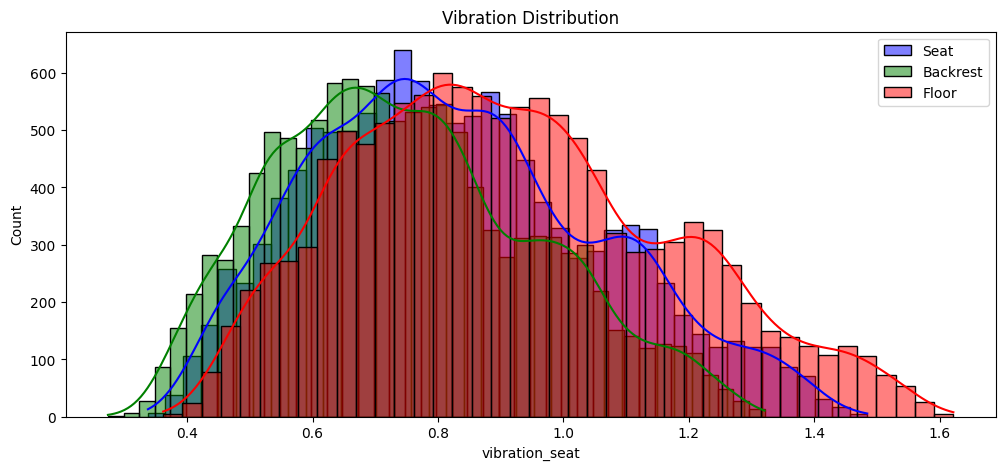

In [11]:
plt.figure(figsize=(12,5))
sns.histplot(y_seat, color='blue', kde=True, label='Seat')
sns.histplot(y_backrest, color='green', kde=True, label='Backrest')
sns.histplot(y_floor, color='red', kde=True, label='Floor')
plt.title("Vibration Distribution")
plt.legend()
plt.show()

In [12]:
def fitness_function(features_mask):
    """
    Fitness function for PSO (minimize RMSE of XGBoost using selected features)
    features_mask: [n_particles, n_features]
    """
    n_particles = features_mask.shape[0]
    scores = []
    
    for i in range(n_particles):
        mask = features_mask[i] > 0.5
        if np.sum(mask) == 0:
            scores.append(1e6)
            continue
        X_masked = X_scaled[:, mask]
        X_train, X_val, y_train, y_val = train_test_split(X_masked, y_seat, test_size=0.2, random_state=42)
        model = xgb.XGBRegressor(max_depth=4,
                                 min_child_weight=3,
                                 learning_rate=0.25,
                                 n_estimators=128,
                                 reg_alpha=0.6,
                                 reg_lambda=0.8,
                                 verbosity=0)
        model.fit(X_train, y_train)
        preds = model.predict(X_val)
        rmse = np.sqrt(mean_squared_error(y_val, preds))
        scores.append(rmse)
    return np.array(scores)

In [13]:
import pyswarms as ps

n_features = X_scaled.shape[1]

options = {
    'c1': 0.5,
    'c2': 0.3,
    'w': 0.9,
    'k': 3,   # required by PySwarms, ignored for global topology
    'p': 2  # required by PySwarms, ignored for global topology
}

optimizer = ps.discrete.BinaryPSO(
    n_particles=10,
    dimensions=n_features,
    options=options
)

best_cost, best_pos = optimizer.optimize(fitness_function, iters=5)
selected_features = X.columns[best_pos > 0.5]
#print("Selected features by PSO:", selected_features.tolist())

2026-03-15 11:50:18,297 - pyswarms.discrete.binary - INFO - Optimize for 5 iters with {'c1': 0.5, 'c2': 0.3, 'w': 0.9, 'k': 3, 'p': 2}
pyswarms.discrete.binary: 100%|███████████████████████████████████████████████████████████████████████████████|5/5, best_cost=0.0762
2026-03-15 11:50:26,862 - pyswarms.discrete.binary - INFO - Optimization finished | best cost: 0.07620874420766421, best pos: [1 0 1 1 1 0 0 0 1 1 0]


In [14]:
df_pro = df[['suspension', 'speed_m_s', 'tire_pressure_kPa', 'wheelbase_m', 'soil_type', 'soil_moisture_pct', 'tractive_force_kN', 'tool_depth_m','vibration_seat', 'vibration_backrest', 'vibration_floor']]

In [15]:
df_pro.to_csv('processed.csv')

# Seat Vibrations

In [16]:
X = df_pro[['suspension', 'speed_m_s', 'tire_pressure_kPa', 'wheelbase_m', 'soil_type', 'soil_moisture_pct', 'tractive_force_kN', 'tool_depth_m']]
y = df_pro["vibration_seat"]

In [17]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((9920, 8), (2480, 8), (9920,), (2480,))

In [18]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, mean_absolute_percentage_error
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

ML_Model = []
mape = []
rmse = []
mae = []
r2 = []

def storeResults(model, a, b, c, d):
    ML_Model.append(model) 
    mape.append(round(a, 3)) 
    rmse.append(round(b, 3))
    mae.append(round(c, 3))
    r2.append(round(d, 3))

# XGBoost

In [19]:
xgb_model = xgb.XGBRegressor(
    max_depth=4,
    min_child_weight=3,
    learning_rate=0.25,
    n_estimators=128,
    reg_alpha=0.6,
    reg_lambda=0.8,
    verbosity=0
)
xgb_model.fit(X_train, y_train)
y_pred = xgb_model.predict(X_test)

In [20]:
xgb_mape = mean_absolute_percentage_error(y_test, y_pred)
xgb_rmse = mean_squared_error(y_test, y_pred, squared=False)
xgb_mae = mean_absolute_error(y_test, y_pred)
xgb_r2 = r2_score(y_test, y_pred)

In [21]:
storeResults("XGBoost", xgb_mape, xgb_rmse, xgb_mae, xgb_r2)

# ANN

In [22]:
ann = Sequential()
# Layer 1
ann.add(Dense(256, input_dim=X_train.shape[1]))
ann.add(LeakyReLU())
# Layers 2-5
for _ in range(4):
    ann.add(Dense(64))
    ann.add(LeakyReLU())
# Output layer
ann.add(Dense(1, activation='linear'))

optimizer_ann = Adam(learning_rate=0.001)
ann.compile(loss='mse', optimizer=optimizer_ann)
ann.fit(X_train, y_train, epochs=50, batch_size=32, verbose=0)

In [23]:
y_pred = ann.predict(X_test)

ann_mape = mean_absolute_percentage_error(y_test, y_pred)
ann_rmse = mean_squared_error(y_test, y_pred, squared=False)
ann_mae = mean_absolute_error(y_test, y_pred)
ann_r2 = r2_score(y_test, y_pred)

78/78 [==============================] - 0s 1ms/step


In [24]:
storeResults("ANN", ann_mape, ann_rmse, ann_mae, ann_r2)

# Gaussian Process

In [25]:
kernel = ConstantKernel(1.0) * RBF(length_scale=1.0)
gpr = GaussianProcessRegressor(kernel=kernel, alpha=1.0)
gpr.fit(X_train, y_train)

GaussianProcessRegressor(alpha=1.0, kernel=1**2 * RBF(length_scale=1))

In [26]:
y_pred = gpr.predict(X_test)

gp_mape = mean_absolute_percentage_error(y_test, y_pred)
gp_rmse = mean_squared_error(y_test, y_pred, squared=False)
gp_mae = mean_absolute_error(y_test, y_pred)
gp_r2 = r2_score(y_test, y_pred)

In [27]:
storeResults("GaussianProcess", gp_mape, gp_rmse, gp_mae, gp_r2)

# SVM

In [28]:
from sklearn.svm import LinearSVR
svm_model = LinearSVR(C=1.0, max_iter=100)
svm_model.fit(X_train, y_train)

LinearSVR(max_iter=100)

In [29]:
y_pred = svm_model.predict(X_test)

svm_mape = mean_absolute_percentage_error(y_test, y_pred)
svm_rmse = mean_squared_error(y_test, y_pred, squared=False)
svm_mae = mean_absolute_error(y_test, y_pred)
svm_r2 = r2_score(y_test, y_pred)

In [30]:
storeResults("SVM", svm_mape, svm_rmse, svm_mae, svm_r2)

In [31]:
from sklearn.ensemble import GradientBoostingRegressor,  VotingRegressor
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

In [32]:
xgb = XGBRegressor(
    n_estimators=1200,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

gbr = GradientBoostingRegressor(
    n_estimators=1200,
    learning_rate=0.03,
    max_depth=5,
    random_state=42
)

lgbm = LGBMRegressor(
    n_estimators=1200,
    learning_rate=0.03,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

cat = CatBoostRegressor(
    iterations=1200,
    learning_rate=0.03,
    depth=6,
    loss_function='RMSE',
    verbose=0,
    random_state=42
)

voting = VotingRegressor(
    estimators=[
        ('xgb', xgb),
        ('gbr', gbr),
        ('lgbm', lgbm),
        ('cat', cat)
    ],
    weights=[3, 1, 3, 2]
)

voting.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000848 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 1035
[LightGBM] [Info] Number of data points in the train set: 9920, number of used features: 8
[LightGBM] [Info] Start training from score 0.831361


VotingRegressor(estimators=[('xgb',
                             XGBRegressor(base_score=None, booster=None,
                                          callbacks=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=0.8, device=None,
                                          early_stopping_rounds=None,
                                          enable_categorical=False,
                                          eval_metric=None, feature_types=None,
                                          gamma=None, grow_policy=None,
                                          importance_type=None,
                                          interaction_constraints=None,
                                          learning_rate=...
                                          num_parallel_tree=None,
                                          random_state=42, ...)),
       

In [33]:
y_pred = voting.predict(X_test)

vr_mape = mean_absolute_percentage_error(y_test, y_pred)
vr_rmse = mean_squared_error(y_test, y_pred, squared=False)
vr_mae = mean_absolute_error(y_test, y_pred)
vr_r2 = r2_score(y_test, y_pred)

In [35]:
storeResults("VotingRegressor", vr_mape, vr_rmse, vr_mae, vr_r2)

# Comparison

In [36]:
result = pd.DataFrame({ 'ML Model' : ML_Model,
                        'MAPE' : mape,
                        'RMSE': rmse,
                        'MAE'   : mae,
                        'R2-Score': r2                        
                      })

In [37]:
result

,ML Model,MAPE,RMSE,MAE,R2-Score
0,XGBoost,0.023,0.022,0.017,0.991
1,ANN,0.032,0.032,0.026,0.980
2,GaussianProcess,0.250,0.228,0.187,-0.000
3,SVM,0.045,0.042,0.034,0.965
4,VotingRegressor,0.022,0.021,0.017,0.992


# Modelling

In [38]:
import joblib

joblib.dump(voting, "Models/model_seat.sav")

['Models/model_seat.sav']

# Graph

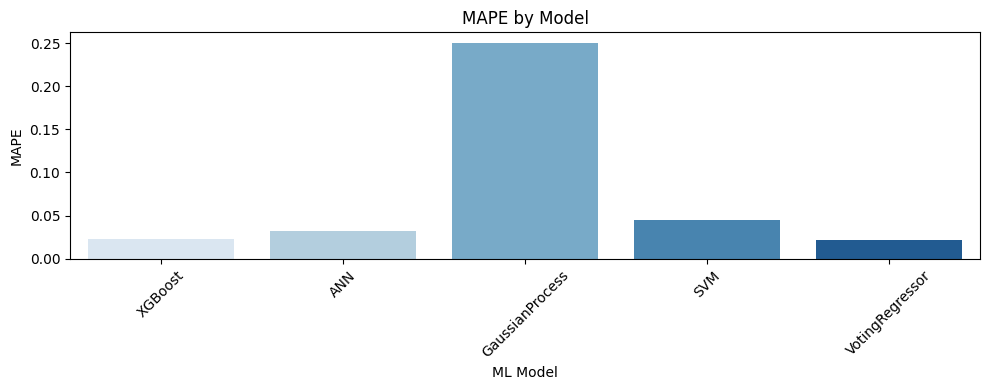

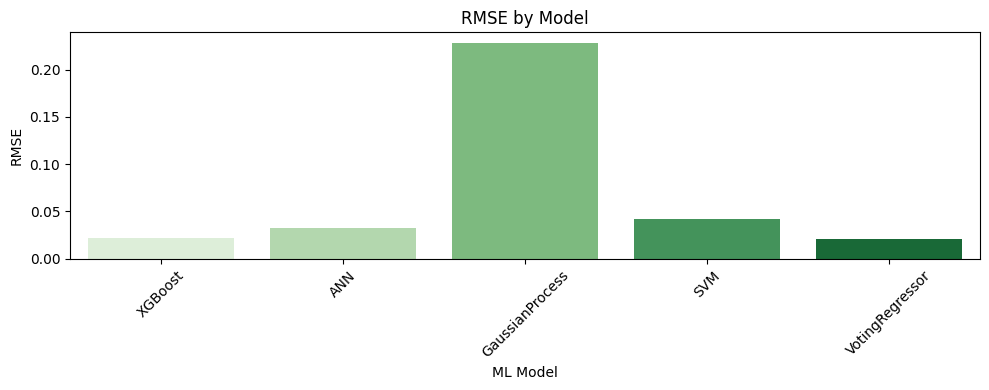

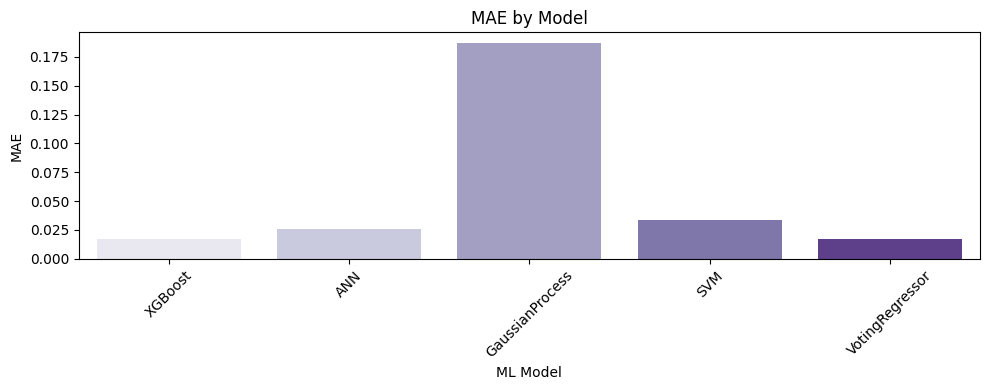

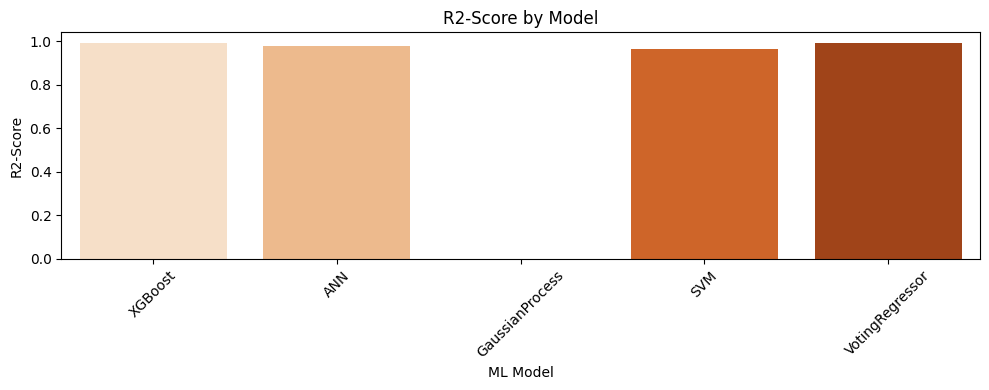

In [39]:
palettes = {
    'MAPE': 'Blues',
    'RMSE': 'Greens',
    'MAE': 'Purples',
    'R2-Score': 'Oranges'
}

for metric in ['MAPE', 'RMSE', 'MAE', 'R2-Score']:
    plt.figure(figsize=(10, 4))
    sns.barplot(data=result, x='ML Model', y=metric, palette=palettes[metric])
    plt.title(f'{metric} by Model')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# BackRest Vibration

In [40]:
X = df_pro[['suspension', 'speed_m_s', 'tire_pressure_kPa', 'wheelbase_m', 'soil_type', 'soil_moisture_pct', 'tractive_force_kN', 'tool_depth_m']]
y = df_pro["vibration_backrest"]

In [41]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((9920, 8), (2480, 8), (9920,), (2480,))

In [42]:
ML_Model = []
mape = []
rmse = []
mae = []
r2 = []

def storeResults(model, a, b, c, d):
    ML_Model.append(model) 
    mape.append(round(a, 3)) 
    rmse.append(round(b, 3))
    mae.append(round(c, 3))
    r2.append(round(d, 3))

# XGBoost

In [44]:
xgb_model = XGBRegressor(
    max_depth=4,
    min_child_weight=3,
    learning_rate=0.25,
    n_estimators=128,
    reg_alpha=0.6,
    reg_lambda=0.8,
    verbosity=0
)
xgb_model.fit(X_train, y_train)
y_pred = xgb_model.predict(X_test)

In [45]:
xgb_mape = mean_absolute_percentage_error(y_test, y_pred)
xgb_rmse = mean_squared_error(y_test, y_pred, squared=False)
xgb_mae = mean_absolute_error(y_test, y_pred)
xgb_r2 = r2_score(y_test, y_pred)

In [46]:
storeResults("XGBoost", xgb_mape, xgb_rmse, xgb_mae, xgb_r2)

# ANN

In [47]:
ann = Sequential()
# Layer 1
ann.add(Dense(256, input_dim=X_train.shape[1]))
ann.add(LeakyReLU())
# Layers 2-5
for _ in range(4):
    ann.add(Dense(64))
    ann.add(LeakyReLU())
# Output layer
ann.add(Dense(1, activation='linear'))

optimizer_ann = Adam(learning_rate=0.001)
ann.compile(loss='mse', optimizer=optimizer_ann)
ann.fit(X_train, y_train, epochs=50, batch_size=32, verbose=0)

In [48]:
y_pred = ann.predict(X_test)

ann_mape = mean_absolute_percentage_error(y_test, y_pred)
ann_rmse = mean_squared_error(y_test, y_pred, squared=False)
ann_mae = mean_absolute_error(y_test, y_pred)
ann_r2 = r2_score(y_test, y_pred)

78/78 [==============================] - 0s 1ms/step


In [49]:
storeResults("ANN", ann_mape, ann_rmse, ann_mae, ann_r2)

# Gaussian Process

In [50]:
kernel = ConstantKernel(1.0) * RBF(length_scale=1.0)
gpr = GaussianProcessRegressor(kernel=kernel, alpha=1.0)
gpr.fit(X_train, y_train)

GaussianProcessRegressor(alpha=1.0, kernel=1**2 * RBF(length_scale=1))

In [51]:
y_pred = gpr.predict(X_test)

gp_mape = mean_absolute_percentage_error(y_test, y_pred)
gp_rmse = mean_squared_error(y_test, y_pred, squared=False)
gp_mae = mean_absolute_error(y_test, y_pred)
gp_r2 = r2_score(y_test, y_pred)

In [52]:
storeResults("GaussianProcess", gp_mape, gp_rmse, gp_mae, gp_r2)

# SVM

In [53]:
from sklearn.svm import LinearSVR
svm_model = LinearSVR(C=1.0, max_iter=100)
svm_model.fit(X_train, y_train)

LinearSVR(max_iter=100)

In [54]:
y_pred = svm_model.predict(X_test)

svm_mape = mean_absolute_percentage_error(y_test, y_pred)
svm_rmse = mean_squared_error(y_test, y_pred, squared=False)
svm_mae = mean_absolute_error(y_test, y_pred)
svm_r2 = r2_score(y_test, y_pred)

In [55]:
storeResults("SVM", svm_mape, svm_rmse, svm_mae, svm_r2)

# Ensemble Model

In [56]:
xgb = XGBRegressor(
    n_estimators=1200,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

gbr = GradientBoostingRegressor(
    n_estimators=1200,
    learning_rate=0.03,
    max_depth=5,
    random_state=42
)

lgbm = LGBMRegressor(
    n_estimators=1200,
    learning_rate=0.03,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

cat = CatBoostRegressor(
    iterations=1200,
    learning_rate=0.03,
    depth=6,
    loss_function='RMSE',
    verbose=0,
    random_state=42
)

voting = VotingRegressor(
    estimators=[
        ('xgb', xgb),
        ('gbr', gbr),
        ('lgbm', lgbm),
        ('cat', cat)
    ],
    weights=[3, 1, 3, 2]
)

voting.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000355 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1035
[LightGBM] [Info] Number of data points in the train set: 9920, number of used features: 8
[LightGBM] [Info] Start training from score 0.748125


VotingRegressor(estimators=[('xgb',
                             XGBRegressor(base_score=None, booster=None,
                                          callbacks=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=0.8, device=None,
                                          early_stopping_rounds=None,
                                          enable_categorical=False,
                                          eval_metric=None, feature_types=None,
                                          gamma=None, grow_policy=None,
                                          importance_type=None,
                                          interaction_constraints=None,
                                          learning_rate=...
                                          num_parallel_tree=None,
                                          random_state=42, ...)),
       

In [57]:
y_pred = voting.predict(X_test)

vr_mape = mean_absolute_percentage_error(y_test, y_pred)
vr_rmse = mean_squared_error(y_test, y_pred, squared=False)
vr_mae = mean_absolute_error(y_test, y_pred)
vr_r2 = r2_score(y_test, y_pred)

In [58]:
storeResults("VotingRegressor", vr_mape, vr_rmse, vr_mae, vr_r2)

# Comparison

In [59]:
result = pd.DataFrame({ 'ML Model' : ML_Model,
                        'MAPE' : mape,
                        'RMSE': rmse,
                        'MAE'   : mae,
                        'R2-Score': r2                        
                      })

In [60]:
result

,ML Model,MAPE,RMSE,MAE,R2-Score
0,XGBoost,0.025,0.022,0.017,0.989
1,ANN,0.042,0.035,0.029,0.971
2,GaussianProcess,0.251,0.205,0.168,-0.000
3,SVM,0.088,0.069,0.060,0.886
4,VotingRegressor,0.024,0.021,0.017,0.990


# Modelling

In [61]:
joblib.dump(voting, "Models/model_backrest.sav")

['Models/model_backrest.sav']

# Graph

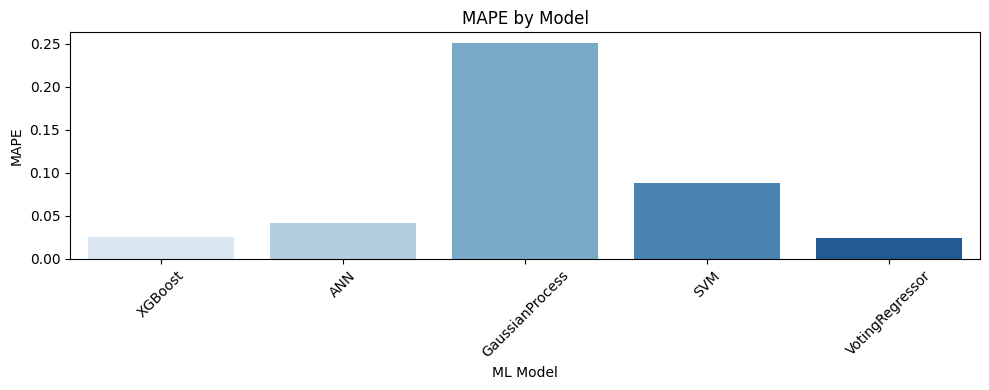

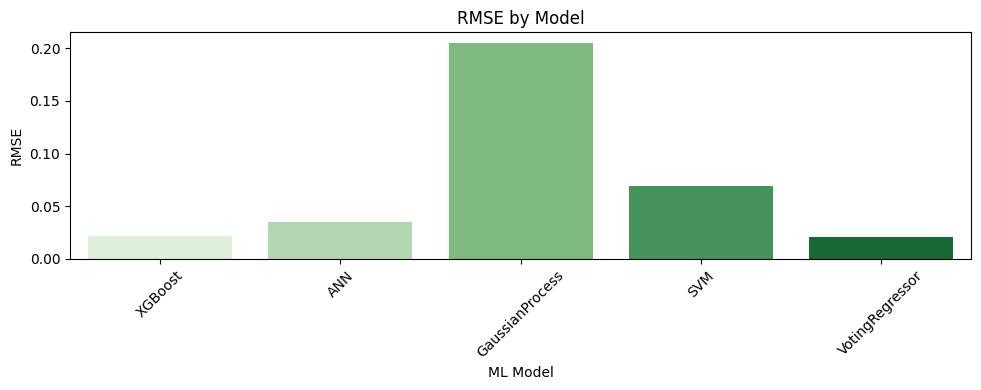

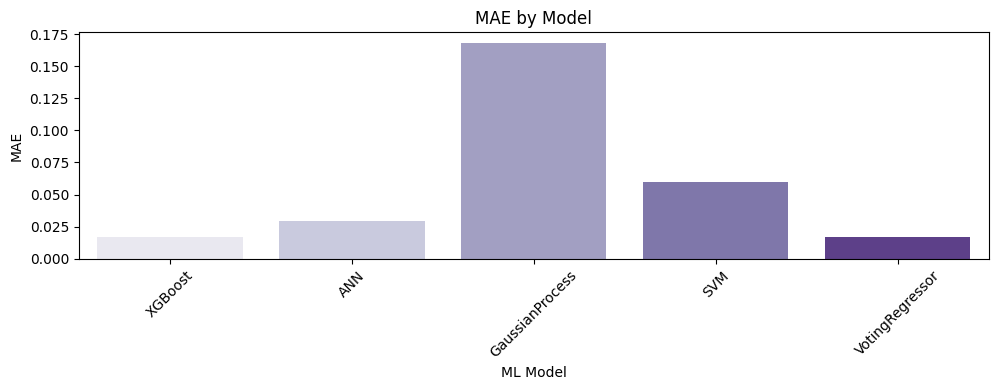

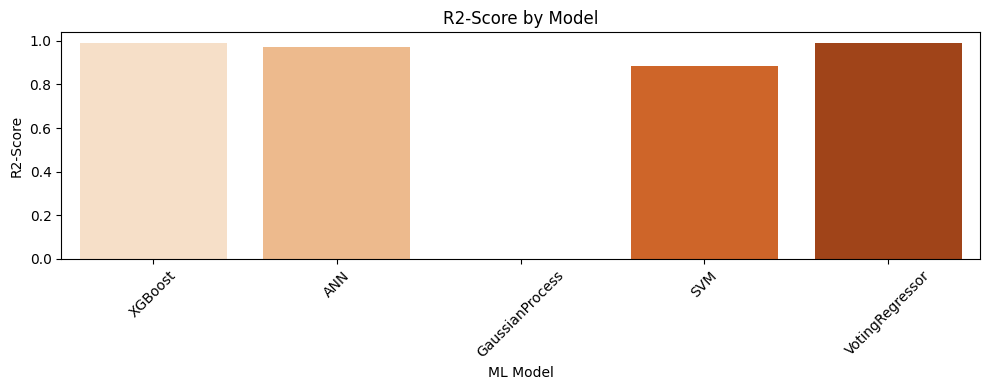

In [62]:
palettes = {
    'MAPE': 'Blues',
    'RMSE': 'Greens',
    'MAE': 'Purples',
    'R2-Score': 'Oranges'
}

for metric in ['MAPE', 'RMSE', 'MAE', 'R2-Score']:
    plt.figure(figsize=(10, 4))
    sns.barplot(data=result, x='ML Model', y=metric, palette=palettes[metric])
    plt.title(f'{metric} by Model')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

# Floor Vibrations

In [63]:
X = df_pro[['suspension', 'speed_m_s', 'tire_pressure_kPa', 'wheelbase_m', 'soil_type', 'soil_moisture_pct', 'tractive_force_kN', 'tool_depth_m']]
y = df_pro["vibration_floor"]

In [64]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train.shape, X_test.shape, y_train.shape, y_test.shape

((9920, 8), (2480, 8), (9920,), (2480,))

In [65]:
ML_Model = []
mape = []
rmse = []
mae = []
r2 = []

def storeResults(model, a, b, c, d):
    ML_Model.append(model) 
    mape.append(round(a, 3)) 
    rmse.append(round(b, 3))
    mae.append(round(c, 3))
    r2.append(round(d, 3))

# XGBoost

In [66]:
xgb_model = XGBRegressor(
    max_depth=4,
    min_child_weight=3,
    learning_rate=0.25,
    n_estimators=128,
    reg_alpha=0.6,
    reg_lambda=0.8,
    verbosity=0
)
xgb_model.fit(X_train, y_train)
y_pred = xgb_model.predict(X_test)

In [67]:
xgb_mape = mean_absolute_percentage_error(y_test, y_pred)
xgb_rmse = mean_squared_error(y_test, y_pred, squared=False)
xgb_mae = mean_absolute_error(y_test, y_pred)
xgb_r2 = r2_score(y_test, y_pred)

In [68]:
storeResults("XGBoost", xgb_mape, xgb_rmse, xgb_mae, xgb_r2)

# ANN

In [69]:
ann = Sequential()
# Layer 1
ann.add(Dense(256, input_dim=X_train.shape[1]))
ann.add(LeakyReLU())
# Layers 2-5
for _ in range(4):
    ann.add(Dense(64))
    ann.add(LeakyReLU())
# Output layer
ann.add(Dense(1, activation='linear'))

optimizer_ann = Adam(learning_rate=0.001)
ann.compile(loss='mse', optimizer=optimizer_ann)
ann.fit(X_train, y_train, epochs=50, batch_size=32, verbose=0)

In [70]:
y_pred = ann.predict(X_test)

ann_mape = mean_absolute_percentage_error(y_test, y_pred)
ann_rmse = mean_squared_error(y_test, y_pred, squared=False)
ann_mae = mean_absolute_error(y_test, y_pred)
ann_r2 = r2_score(y_test, y_pred)

78/78 [==============================] - 0s 1ms/step


In [71]:
storeResults("ANN", ann_mape, ann_rmse, ann_mae, ann_r2)

# Gaussian Process

In [72]:
kernel = ConstantKernel(1.0) * RBF(length_scale=1.0)
gpr = GaussianProcessRegressor(kernel=kernel, alpha=1.0)
gpr.fit(X_train, y_train)

GaussianProcessRegressor(alpha=1.0, kernel=1**2 * RBF(length_scale=1))

In [73]:
y_pred = gpr.predict(X_test)

gp_mape = mean_absolute_percentage_error(y_test, y_pred)
gp_rmse = mean_squared_error(y_test, y_pred, squared=False)
gp_mae = mean_absolute_error(y_test, y_pred)
gp_r2 = r2_score(y_test, y_pred)

In [74]:
storeResults("GaussianProcess", gp_mape, gp_rmse, gp_mae, gp_r2)

# SVM

In [75]:
svm_model = LinearSVR(C=1.0, max_iter=100)
svm_model.fit(X_train, y_train)

LinearSVR(max_iter=100)

In [76]:
y_pred = svm_model.predict(X_test)

svm_mape = mean_absolute_percentage_error(y_test, y_pred)
svm_rmse = mean_squared_error(y_test, y_pred, squared=False)
svm_mae = mean_absolute_error(y_test, y_pred)
svm_r2 = r2_score(y_test, y_pred)

In [77]:
storeResults("SVM", svm_mape, svm_rmse, svm_mae, svm_r2)

# Ensemble Model

In [78]:
xgb = XGBRegressor(
    n_estimators=1200,
    learning_rate=0.03,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

gbr = GradientBoostingRegressor(
    n_estimators=1200,
    learning_rate=0.03,
    max_depth=5,
    random_state=42
)

lgbm = LGBMRegressor(
    n_estimators=1200,
    learning_rate=0.03,
    max_depth=-1,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

cat = CatBoostRegressor(
    iterations=1200,
    learning_rate=0.03,
    depth=6,
    loss_function='RMSE',
    verbose=0,
    random_state=42
)

voting = VotingRegressor(
    estimators=[
        ('xgb', xgb),
        ('gbr', gbr),
        ('lgbm', lgbm),
        ('cat', cat)
    ],
    weights=[3, 1, 3, 2]
)

voting.fit(X_train, y_train)

[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.000332 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 1035
[LightGBM] [Info] Number of data points in the train set: 9920, number of used features: 8
[LightGBM] [Info] Start training from score 0.914659


VotingRegressor(estimators=[('xgb',
                             XGBRegressor(base_score=None, booster=None,
                                          callbacks=None,
                                          colsample_bylevel=None,
                                          colsample_bynode=None,
                                          colsample_bytree=0.8, device=None,
                                          early_stopping_rounds=None,
                                          enable_categorical=False,
                                          eval_metric=None, feature_types=None,
                                          gamma=None, grow_policy=None,
                                          importance_type=None,
                                          interaction_constraints=None,
                                          learning_rate=...
                                          num_parallel_tree=None,
                                          random_state=42, ...)),
       

In [79]:
y_pred = voting.predict(X_test)

vr_mape = mean_absolute_percentage_error(y_test, y_pred)
vr_rmse = mean_squared_error(y_test, y_pred, squared=False)
vr_mae = mean_absolute_error(y_test, y_pred)
vr_r2 = r2_score(y_test, y_pred)

In [80]:
storeResults("VotingRegressor", vr_mape, vr_rmse, vr_mae, vr_r2)

# Comparison

In [81]:
result = pd.DataFrame({ 'ML Model' : ML_Model,
                        'MAPE' : mape,
                        'RMSE': rmse,
                        'MAE'   : mae,
                        'R2-Score': r2                        
                      })

In [82]:
result

,ML Model,MAPE,RMSE,MAE,R2-Score
0,XGBoost,0.021,0.022,0.018,0.992
1,ANN,0.031,0.032,0.026,0.983
2,GaussianProcess,0.250,0.251,0.206,-0.000
3,SVM,0.047,0.049,0.039,0.962
4,VotingRegressor,0.020,0.021,0.017,0.993


# Modelling

In [83]:
joblib.dump(voting, "Models/model_floor.sav")

['Models/model_floor.sav']

# Graph

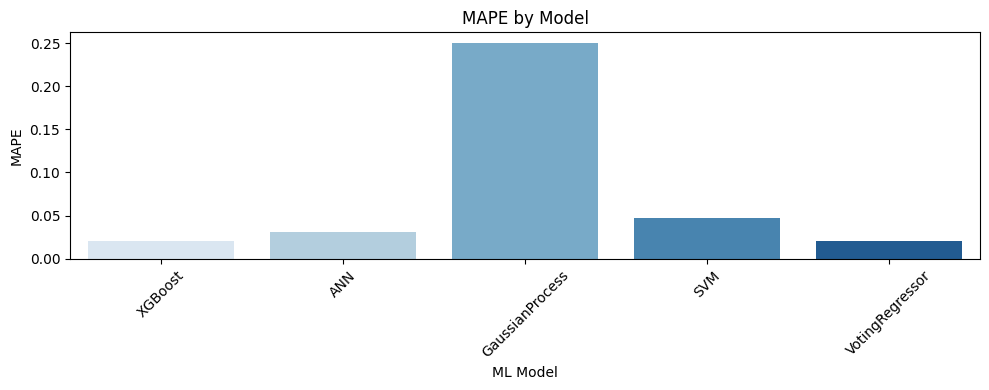

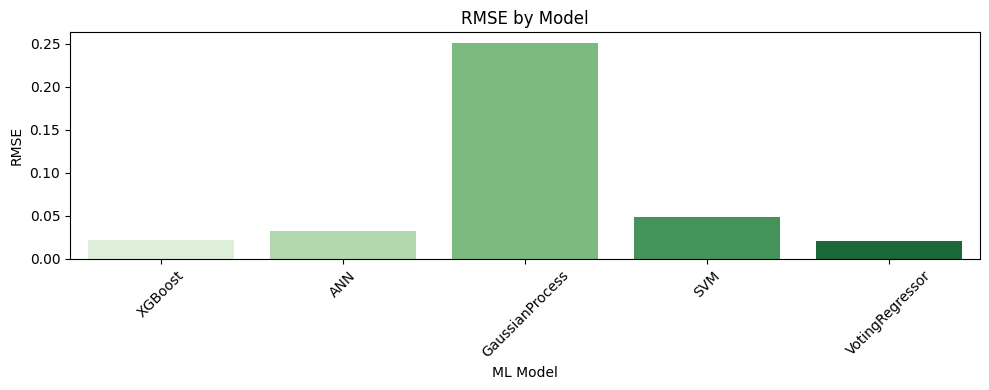

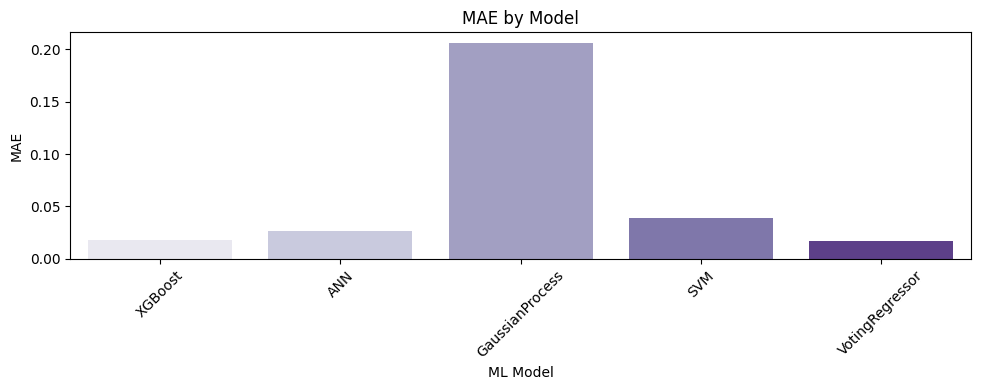

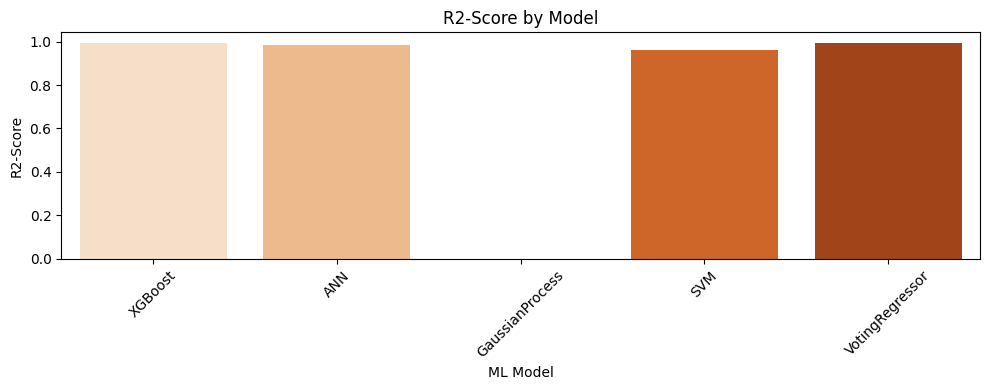

In [84]:
palettes = {
    'MAPE': 'Blues',
    'RMSE': 'Greens',
    'MAE': 'Purples',
    'R2-Score': 'Oranges'
}

for metric in ['MAPE', 'RMSE', 'MAE', 'R2-Score']:
    plt.figure(figsize=(10, 4))
    sns.barplot(data=result, x='ML Model', y=metric, palette=palettes[metric])
    plt.title(f'{metric} by Model')
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()